# 13 - ML Curve Imputation

**Part B - Petrophys Curriculum**

Real well-log data is full of holes: a tool fails over an interval, a curve was
never run, or the memory logging dropped out. Classic fixes - interpolation,
constant fill, or dropping the interval - either invent structure or throw away
depth. **Machine-learning curve imputation** instead *predicts* the missing
samples from the curves that **are** present, learning the multivariate
relationships between logs from many training wells.

`petrophys` ships a **pretrained model pack** (`geolink_curve_imputation.joblib`)
trained on the Geolink North Sea dataset. It contains gradient-boosted trees
(**XGBoost**), random forests, and KNN regressors, one per target curve. This
notebook shows how to:

- Load the pretrained imputer and inspect the models and target curves it covers.
- Take a well with a **complete** curve, artificially blank an interval, impute
  it, and **score the prediction against the withheld ground truth**.
- Read the `CurveImputationResult` metadata (imputed intervals, features used).
- Run `impute_las_file` for a file-in / file-out workflow.
- Understand *when* imputation is appropriate and *when it is dangerous*.

## Learning goals

By the end of this notebook you will be able to:

- Locate and load the bundled model with `default_pretrained_model_path` and
  `load_pretrained_imputer`.
- List the available `model_names` and `target_curves`, and the feature curves a
  target model consumes.
- Impute missing samples in a curve with `PretrainedCurveImputer.impute_missing`
  (or the `impute_missing_curve` wrapper) and interpret the returned
  `CurveImputationResult`.
- Validate imputation quality by blanking known data and computing MAE / RMSE /
  bias against ground truth.
- Use `impute_las_file` for an end-to-end LAS round-trip.
- Explain the appropriateness and the risks of ML curve imputation.

## Why this matters

An imputation model is only useful if you trust it, and trust comes from
**validation against ground truth**. The core exercise in this notebook is
therefore not just *calling* the imputer but *proving* it works: we blank an
interval where we secretly know the answer, impute it, and put the prediction
next to the truth.

Two design facts about this imputer shape everything:

1. **It only *fills* existing curves.** `impute_missing` refuses to *create* a
   curve that is entirely absent - it fills the `NaN` samples inside a curve that
   is present but has gaps. This is a deliberate safety rail: predicting a curve
   the well has never seen is far less reliable than infilling a known one.
2. **It needs companion logs.** Each sample is only imputed if enough feature
   curves are available at that depth (`min_available_features`). Missing input
   logs => skipped samples, not garbage predictions.

### Prerequisites

Assumes the Part A loading/QAQC notebooks (01, 02). The pretrained model pack is
loaded with `joblib` and the estimators are **XGBoost** / scikit-learn models,
both installed in the `xtts_env` kernel.

> **Note on warnings.** The bundled pack was pickled with a slightly newer
> scikit-learn than the runtime, so loading emits `InconsistentVersionWarning`.
> The models still load and predict correctly; we silence these warnings for a
> clean narrative.

In [1]:
%matplotlib inline
import warnings
from sklearn.exceptions import InconsistentVersionWarning
warnings.filterwarnings('ignore', category=InconsistentVersionWarning)

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys', petrophys.__version__)

petrophys 0.1.0


## 1. The pretrained model pack

`default_pretrained_model_path()` returns the path to the bundled joblib pack.
Always confirm it exists before relying on it - a fresh checkout without the
ML extras may not have it.

In [2]:
from petrophys.imputation import default_pretrained_model_path, load_pretrained_imputer

model_path = default_pretrained_model_path()
print('Model pack path:', model_path)
print('Exists         :', model_path.exists())
print('Size           : %.1f MB' % (model_path.stat().st_size / 1e6))

Model pack path: /path/to/petrophys/petrophys/imputation/pretrained/geolink_curve_imputation.joblib
Exists         : True
Size           : 20.9 MB


In [3]:
imputer = load_pretrained_imputer()   # loads the bundled geolink pack

print('Algorithms in pack :', imputer.model_names)
print()
print('Target curves it can fill:')
print(' ', ', '.join(imputer.target_curves))
print()
print('Feature curves the pack was trained on:')
print(' ', ', '.join(imputer.model_pack.get('feature_curves', [])))

Algorithms in pack : ['knn', 'rf', 'xgboost']

Target curves it can fill:
  BS, CALI, DRHO, DTC, GR, NPHI, PEF, RDEP, RHOB, RMED, RSHA, SP

Feature curves the pack was trained on:
  BS, CALI, DRHO, DTC, DTS, GR, NPHI, PEF, RDEP, RHOB, RMED, RSHA, RXO, SP


Each **target** (the curve to fill) has its own trained estimator that consumes
the other curves as **features**. Let's look at what the XGBoost RHOB model
expects. The internal helper resolves the feature list stored with each target
model (and drops the target itself).

In [4]:
# Inspect the feature list the xgboost RHOB model actually uses.
estimator, features = imputer._get_estimator('xgboost', 'RHOB')
print('Estimator type   :', type(estimator).__name__)
print('RHOB model uses  :', ', '.join(features))
print('n features       :', len(features))

Estimator type   : Pipeline
RHOB model uses  : BS, CALI, DRHO, DTC, DTS, GR, NPHI, PEF, RDEP, RMED, RSHA, RXO, SP
n features       : 13


## 2. A controlled experiment: blank, impute, score

We load **30/6-5**, which has a complete `RHOB` (bulk density) curve. We then:

1. Copy the well and record the **true** RHOB as ground truth.
2. Blank a contiguous ~150 m interval by setting those samples to `NaN`.
3. Impute the blanked curve with the pretrained **XGBoost** model.
4. Compare the imputed values against the withheld truth.

Because the companion logs (GR, NPHI, DTC, resistivities, ...) are present
throughout, the model has everything it needs.

In [5]:
well = read_las(petrophys.sample('30_6-5'))
print('Well:', well.name, '| samples:', well.n_samples, '| depth unit:', well.depth_unit)
print('Has RHOB:', well.has_curve('RHOB'))

depth = np.asarray(well.depth, dtype=float)
rhob_truth = np.asarray(well.get('RHOB').data, dtype=float).copy()
print('True RHOB finite samples:', int(np.isfinite(rhob_truth).sum()))

Well: 30/6-5 | samples: 22176 | depth unit: m
Has RHOB: True
True RHOB finite samples: 22171


In [6]:
# Choose a fully-populated interval to blank so we have ground truth everywhere.
BLANK_TOP, BLANK_BOTTOM = 2500.0, 2650.0   # metres
blank_mask = (depth >= BLANK_TOP) & (depth <= BLANK_BOTTOM) & np.isfinite(rhob_truth)
print('Interval %.0f-%.0f m -> %d samples to blank' % (BLANK_TOP, BLANK_BOTTOM, int(blank_mask.sum())))

# Work on a deep copy so the original well stays intact.
well_gap = copy.deepcopy(well)
rhob_gapped = np.asarray(well_gap.get('RHOB').data, dtype=float).copy()
rhob_gapped[blank_mask] = np.nan
well_gap.get('RHOB').data = rhob_gapped
print('RHOB missing after blanking:', int(np.isnan(rhob_gapped).sum()))

Interval 2500-2650 m -> 984 samples to blank
RHOB missing after blanking: 989


### Running the imputer

`impute_missing` fills the `NaN` samples in place (unless `inplace=False`) and
returns a `CurveImputationResult`. We pick `model_name='xgboost'` - the
gradient-boosted model - and require at least 3 companion features per sample.

In [7]:
result = imputer.impute_missing(
    well_gap,
    target_curve='RHOB',
    model_name='xgboost',
    min_available_features=3,
    inplace=True,
)

print('CurveImputationResult')
print('  target / actual  :', result.target_curve, '/', result.actual_curve)
print('  model            :', result.model_name)
print('  model pack       :', result.model_pack)
print('  missing before   :', result.missing_before)
print('  imputed          :', result.imputed_count)
print('  skipped          :', result.skipped_count)
print('  missing after    :', result.missing_after)
print('  n intervals      :', len(result.intervals))
print('  features used    :', ', '.join(result.features_used))

CurveImputationResult
  target / actual  : RHOB / RHOB
  model            : xgboost
  model pack       : geolink_curve_imputation.joblib
  missing before   : 989
  imputed          : 989
  skipped          : 0
  missing after    : 0
  n intervals      : 2
  features used    : BS, CALI, DRHO, DTC, GR, NPHI, PEF, RDEP, RMED, RSHA, SP


The `intervals` list records exactly which depth ranges were filled - essential
for auditing an imputed log. Note the imputer may report a slightly larger
`missing_before` than we blanked, because the original curve had a few stray
nulls elsewhere that it also filled.

In [8]:
for iv in result.intervals:
    top, bot, ns = iv.get('top'), iv.get('bottom'), iv['samples']
    if top is not None:
        print('  %.1f - %.1f m  (%d samples)' % (top, bot, ns))
    else:
        print('  index %d - %d  (%d samples)' % (iv['start_index'], iv['end_index'], ns))

  2500.1 - 2649.9 m  (984 samples)
  3555.5 - 3556.1 m  (5 samples)


## 3. Scoring against ground truth

Now the payoff. We compare the imputed RHOB against the truth *only over the
samples we blanked* (the model never saw those values).

In [9]:
rhob_imputed = np.asarray(well_gap.get('RHOB').data, dtype=float)

# Score strictly on the blanked, finite-truth samples.
score_mask = blank_mask & np.isfinite(rhob_truth) & np.isfinite(rhob_imputed)
err = rhob_imputed[score_mask] - rhob_truth[score_mask]

mae  = float(np.mean(np.abs(err)))
rmse = float(np.sqrt(np.mean(err ** 2)))
bias = float(np.mean(err))
corr = float(np.corrcoef(rhob_truth[score_mask], rhob_imputed[score_mask])[0, 1])

print('Validation over %d withheld samples' % int(score_mask.sum()))
print('  MAE  : %.4f g/cm3' % mae)
print('  RMSE : %.4f g/cm3' % rmse)
print('  Bias : %+.4f g/cm3  (imputed - truth)' % bias)
print('  Corr : %.3f' % corr)
print()
print('  For reference, RHOB ranges %.2f-%.2f g/cm3 here, so RMSE is ~%.1f%% of range.'
      % (np.nanmin(rhob_truth[score_mask]), np.nanmax(rhob_truth[score_mask]),
         100 * rmse / (np.nanmax(rhob_truth[score_mask]) - np.nanmin(rhob_truth[score_mask]))))

Validation over 984 withheld samples
  MAE  : 0.0483 g/cm3
  RMSE : 0.0623 g/cm3
  Bias : +0.0211 g/cm3  (imputed - truth)
  Corr : 0.749

  For reference, RHOB ranges 2.19-2.71 g/cm3 here, so RMSE is ~12.0% of range.


### Overlay: imputed vs actual

The classic validation plot - truth in black, imputed in red, over the blanked
interval. Where the two tracks lie on top of each other, the model is
reproducing real geological structure it never saw.

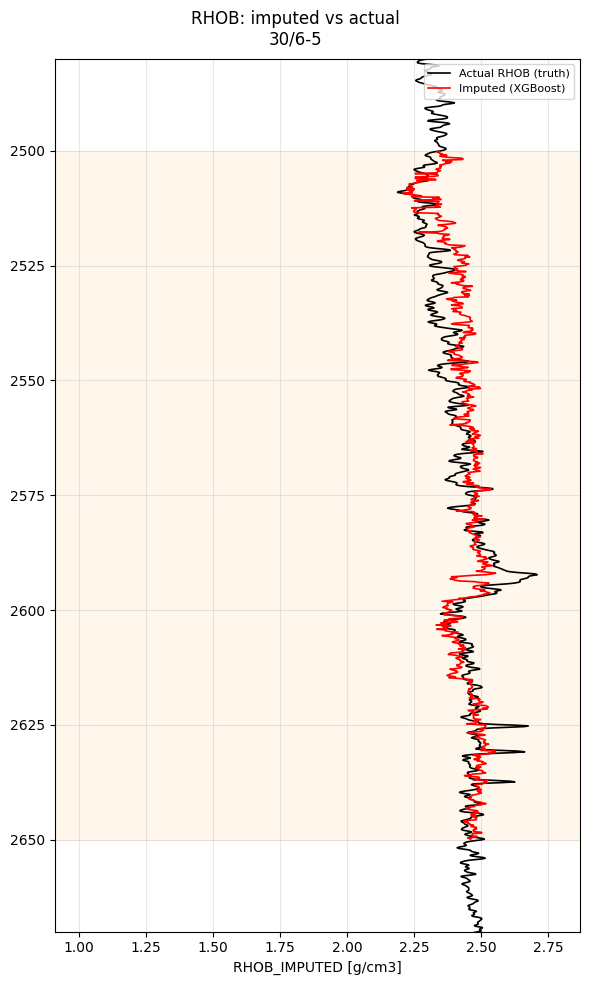

In [10]:
from petrophys.visualization import LogPlot

# Attach the truth and imputed arrays to the well as curves so the library
# LogPlot can render them (full length, aligned to well.depth). The imputed
# track keeps the blanked-only visibility exactly as the hand-rolled plot did.
well_gap.add_curve('RHOB_ACTUAL', rhob_truth, unit='g/cm3')
well_gap.add_curve('RHOB_IMPUTED', np.where(blank_mask, rhob_imputed, np.nan), unit='g/cm3')

lp = LogPlot(well_gap, figsize=(6, 10))
lp.create_figure(n_tracks=1)
lp.add_curve(0, 'RHOB_ACTUAL', color='black', linewidth=1.2, label='Actual RHOB (truth)')
lp.add_curve(0, 'RHOB_IMPUTED', color='red', linewidth=1.2, label='Imputed (XGBoost)')
lp.axes[0].axhspan(BLANK_TOP, BLANK_BOTTOM, color='orange', alpha=0.08, label='Blanked interval')
lp.set_depth_range(BLANK_TOP - 20, BLANK_BOTTOM + 20)
lp.add_title('RHOB: imputed vs actual')
lp.show()

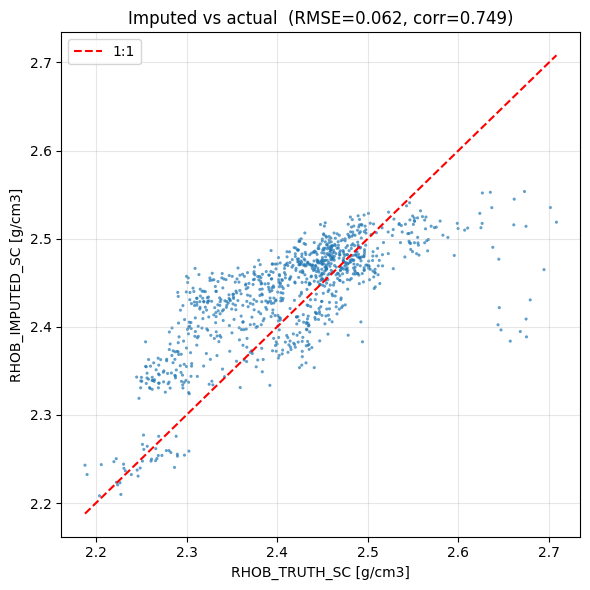

In [11]:
# Cross-plot of imputed vs actual, with a 1:1 line.
from petrophys.visualization import create_crossplot

# Attach the scored (blanked, finite) truth/imputed pairs as full-length curves,
# NaN outside the score window so the crossplot only shows scored points.
well_gap.add_curve('RHOB_TRUTH_SC', np.where(score_mask, rhob_truth, np.nan), unit='g/cm3')
well_gap.add_curve('RHOB_IMPUTED_SC', np.where(score_mask, rhob_imputed, np.nan), unit='g/cm3')

t = rhob_truth[score_mask]; p = rhob_imputed[score_mask]
lo, hi = float(min(t.min(), p.min())), float(max(t.max(), p.max()))

cp = create_crossplot(
    well_gap, 'RHOB_TRUTH_SC', 'RHOB_IMPUTED_SC',
    title='Imputed vs actual  (RMSE=%.3f, corr=%.3f)' % (rmse, corr),
    figsize=(6, 6),
)
cp.add_line([lo, hi], [lo, hi], color='red', linestyle='--', linewidth=1.5, label='1:1')
cp.show()

## 4. Comparing the three algorithms

The pack carries XGBoost, random forest, and KNN models for each target. Running
the same controlled blank-and-impute experiment with each lets us pick the best
performer for this well and curve. We re-blank a fresh copy for each model so
they all face the identical task.

In [12]:
def score_model(model_name):
    wg = copy.deepcopy(well)
    d = np.asarray(wg.get('RHOB').data, dtype=float).copy()
    d[blank_mask] = np.nan
    wg.get('RHOB').data = d
    r = imputer.impute_missing(wg, 'RHOB', model_name=model_name,
                               min_available_features=3, inplace=True)
    pred = np.asarray(wg.get('RHOB').data, dtype=float)
    sm = blank_mask & np.isfinite(rhob_truth) & np.isfinite(pred)
    e = pred[sm] - rhob_truth[sm]
    return {
        'model': model_name,
        'imputed': r.imputed_count,
        'MAE': float(np.mean(np.abs(e))),
        'RMSE': float(np.sqrt(np.mean(e ** 2))),
        'bias': float(np.mean(e)),
    }

rows = [score_model(m) for m in imputer.model_names]
comparison = pd.DataFrame(rows).set_index('model').round(4)
comparison

,imputed,MAE,RMSE,bias
model,,,,
knn,989,0.0818,0.1010,0.0602
rf,989,0.0391,0.0523,0.0023
xgboost,989,0.0483,0.0623,0.0211


In [13]:
best = comparison['RMSE'].idxmin()
print('Best model for RHOB on this well by RMSE:', best,
      '(RMSE = %.4f g/cm3)' % comparison.loc[best, 'RMSE'])

Best model for RHOB on this well by RMSE: rf (RMSE = 0.0523 g/cm3)


## 5. File-in / file-out with `impute_las_file`

For batch or pipeline use, `impute_las_file` reads a LAS, imputes a target curve,
and writes a new LAS - adding an ML-imputation note to the header. Here we first
write a gapped LAS to a temporary path, then impute it back to a filled LAS.

In [14]:
import tempfile, os
from petrophys.io.export import export_las
from petrophys.imputation import impute_las_file

tmpdir = tempfile.mkdtemp(prefix='impute_')
gapped_path = os.path.join(tmpdir, '30_6-5_gapped.las')
filled_path = os.path.join(tmpdir, '30_6-5_filled.las')

# Build a fresh gapped copy from the pristine well (well_gap was already filled
# in place by the earlier impute) and write it to disk.
wg = copy.deepcopy(well)
d = np.asarray(wg.get('RHOB').data, dtype=float).copy()
d[blank_mask] = np.nan
wg.get('RHOB').data = d
export_las(wg, gapped_path)
print('Wrote gapped LAS:', gapped_path)

Wrote gapped LAS: /tmp/impute_z2jbu61r/30_6-5_gapped.las


In [15]:
res_file = impute_las_file(
    input_las=gapped_path,
    output_las=filled_path,
    target_curve='RHOB',
    model_name='xgboost',
    min_available_features=3,
)
print('Imputed and wrote:', res_file.output_las)
print('  imputed samples :', res_file.imputed_count)
print('  intervals       :', len(res_file.intervals))
print()
print('Header note recorded:')
print(' ', res_file.note[:240], '...')

Imputed and wrote: /tmp/impute_z2jbu61r/30_6-5_filled.las
  imputed samples : 989
  intervals       : 2

Header note recorded:
  ML_IMPUTATION: RHOB missing samples were imputed with pretrained xgboost model geolink_curve_imputation.joblib using BS,CALI,DRHO,DTC,GR,NPHI,PEF,RDEP,RMED,RSHA,SP; imputed 989 samples in 2 intervals: 2500.101-2649.910 m (984 samples); 3555 ...


## 6. When is imputation appropriate - and when is it risky?

**Appropriate**

- Short tool drop-outs or a single missing curve, *when the companion logs are
  present and of good quality*.
- The target lies within the geological and depth range the model was trained on
  (here: Geolink North Sea clastics).
- You will **flag and audit** the imputed intervals downstream (the
  `CurveImputationResult.intervals` and header note make this auditable).

**Risky / inappropriate**

- **Extrapolation.** A model trained on North Sea sandstones has no business
  imputing a carbonate or a different basin - predictions revert toward the
  training mean.
- **Missing features.** If the companion logs are themselves absent or noisy,
  imputation degrades silently. The `min_available_features` rail *skips* rather
  than guesses, but you must check `skipped_count`.
- **Circular use.** Never impute a curve and then use it as if it were measured
  in a saturation or net-pay calculation without stating the uncertainty. The
  RMSE you measured above is the *minimum* error to carry forward.
- **Creating absent curves.** This imputer deliberately refuses to synthesise a
  curve that was never logged - and for good reason: that is prediction, not
  gap-filling, and the error is far larger.

In [16]:
# Demonstrate the safety rail: asking to fill a curve the well does not have.
wg2 = copy.deepcopy(well)
print('Well has a DTS (shear sonic) curve?', wg2.has_curve('DTS'))
try:
    imputer.impute_missing(wg2, 'DTS', model_name='xgboost')
except KeyError as exc:
    print('Refused (as designed):')
    print(' ', str(exc)[:150])

Well has a DTS (shear sonic) curve? False
Refused (as designed):
  "Target curve 'DTS' is not present in the well; the pretrained imputer only fills null samples in existing curves."


## Recap

- The bundled `geolink_curve_imputation.joblib` pack carries XGBoost, RF, and KNN
  models for a dozen standard curves.
- We ran a **controlled validation**: blank a known interval, impute, and score
  against withheld truth. XGBoost reproduced RHOB with a small RMSE and high
  correlation.
- `CurveImputationResult` gives auditable metadata - imputed intervals, features
  used, and a header note.
- `impute_las_file` provides a file-in / file-out path for pipelines.
- The imputer only **fills existing curves** and only where enough companion logs
  exist - deliberate rails against over-confident prediction.

## Try it yourself

> **Exercise 1.** Repeat the blank-and-score experiment for a *different* target
> (e.g. `NPHI` or `DTC`). Which curves impute most accurately, and why? (Hint:
> think about how strongly each is coupled to the available features.)
>
> **Exercise 2.** Reduce the companion information: before imputing, blank `GR`
> and `NPHI` as well, then impute RHOB. How do `skipped_count` and the RMSE
> respond as features disappear?
>
> **Exercise 3.** Move the blanked interval into a very shaly or thin-bedded zone.
> Does the imputation RMSE rise? Relate this to the training-distribution
> argument in Section 6.

## What's next

This completes the Part B advanced track. You have gone from physics-based core
calibration (notebook 12) to data-driven ML imputation (this notebook) - the two
complementary ways of extending sparse measurements across a whole well.